# Projet Deep learning - CNN pour panneaux de signalisation

## Partie 1 - Présentation et traitement du dataset.

### Description du Dataset
Pour ce projet, nous allons utiliser le dataset GTSRB -German Traffics Signs Recognition Benchmark-. Voici ses informations :
- Auteur : Mykola
- License : CC0: Public Domain
- Taille dataset entrainement : 39209 images de panneaux (dans le répertoire d'entrainement)
- Taille dataset Test : 12630 images
- Nombre de classes: 43

### Description classes
Voici les différentes classes et leurs signification, ainsi que la quantité d'images par classe :


In [1]:
from pathlib import Path
import pandas as pd
import trafficsigns.data.observe_dataset as obs
from trafficsigns.config import ROOT

correspondance = {
    0: "Limite de vitesse (20 km/h)",
    1: "Limite de vitesse (30 km/h)",
    2: "Limite de vitesse (50 km/h)",
    3: "Limite de vitesse (60 km/h)",
    4: "Limite de vitesse (70 km/h)",
    5: "Limite de vitesse (80 km/h)",
    6: "Fin de limitation de vitesse (80 km/h)",
    7: "Limite de vitesse (100 km/h)",
    8: "Limite de vitesse (120 km/h)",
    9: "Interdiction de dépasser",
    10: "Interdiction de dépasser pour les véhicules > 3.5 t",
    11: "Interdiction d'intersection / Priorité à la prochaine intersection",
    12: "Route prioritaire",
    13: "Cédez le passage",
    14: "Stop",
    15: "Circulation interdite à tout véhicule dans les deux sens",
    16: "Interdiction d'accès aux véhicules > 3.5 t",
    17: "Sens interdit",
    18: "Danger",
    19: "Virage à gauche",
    20: "Virage à droite",
    21: "Successions de virages",
    22: "Casserole / Route bosselée",
    23: "Chaussée glissante",
    24: "Rétrécissement de la chaussée par la droite",
    25: "Travaux en cours",
    26: "Signaux lumineux / Feux tricolores",
    27: "Passage de piétons",
    28: "Attention enfants",
    29: "Passage de cyclistes",
    30: "Danger neige / verglas",
    31: "Passage d'animaux sauvages",
    32: "Fin de toutes les interdictions précédemment signalées",
    33: "Obligation de tourner à droite",
    34: "Obligation de tourner à gauche",
    35: "Obligation d'aller tout droit",
    36: "Obligation d'aller tout droit ou à droite",
    37: "Obligation d'aller tout droit ou à gauche",
    38: "Contournement obligatoire par la droite",
    39: "Contournement obligatoire par la gauche",
    40: "Rond-point",
    41: "Fin d'interdiction de dépasser",
    42: "Fin d'interdiction de dépasser pour les véhicules > 3.5 t",
}

print("== Quantités de chaque classe du dataset d'entrainement ==")

PATH_TO_FILES = Path.joinpath(ROOT, "data", "raw", "gtsrb")

data_frame = pd.read_csv(filepath_or_buffer=Path.joinpath(PATH_TO_FILES, "Train.csv"))

quantity_frame = obs.get_quantity_of_class(data_frame, "ClassId")

# 1. Mappage des IDs vers les libellés des panneaux
quantity_frame["Panneau"] = quantity_frame["ClassID"].map(correspondance)

# 2. Réorganisation des colonnes pour placer le libellé à côté de l'ID
quantity_frame = quantity_frame[["ClassID", "Panneau", "Quantité"]]

print(quantity_frame)
print(f"Nombre de classes : {len(quantity_frame)}")

== Quantités de chaque classe du dataset d'entrainement ==
    ClassID                                            Panneau  Quantité
0        20                                    Virage à droite       360
1         0                        Limite de vitesse (20 km/h)       210
2         1                        Limite de vitesse (30 km/h)      2220
3         2                        Limite de vitesse (50 km/h)      2250
4         3                        Limite de vitesse (60 km/h)      1410
5         4                        Limite de vitesse (70 km/h)      1980
6         5                        Limite de vitesse (80 km/h)      1860
7         6             Fin de limitation de vitesse (80 km/h)       420
8         7                       Limite de vitesse (100 km/h)      1440
9         8                       Limite de vitesse (120 km/h)      1410
10        9                           Interdiction de dépasser      1470
11       10  Interdiction de dépasser pour les véhicules > ...   

## Dimension des images

Les images ne sont pas toutes de la même taille. La taille s'étend de (25,25)px à (225,243)px avec une médiane de 43px. Nous avons décidé de prendre la puissance de 2 la plus proche de la médiane, c'est-à-dire (32,32)px.

== Informations sur la taille des images ==
         Hauteur  Largeur
Minimum     25.0     25.0
Median      43.0     43.0
Maximum    225.0    243.0


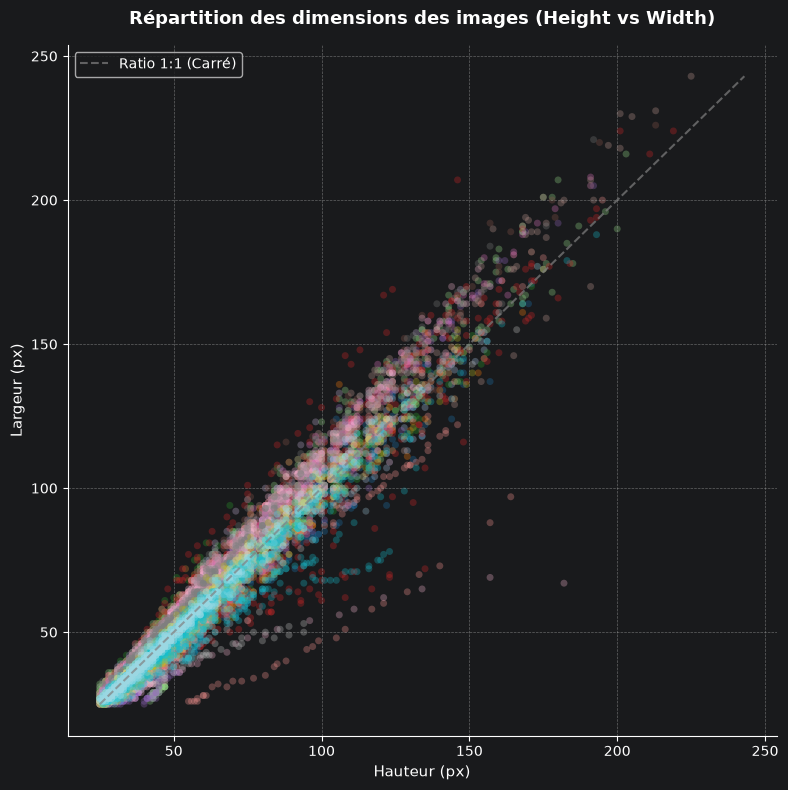

In [2]:
import numpy as np
print("== Informations sur la taille des images ==")

size_dataframe = pd.DataFrame({"Hauteur" : [data_frame['Height'].min(), np.median(np.array(data_frame['Height'])), data_frame['Height'].max()], "Largeur" : [data_frame['Width'].min(), np.median(np.array(data_frame['Width'])), data_frame['Width'].max()]}, index=["Minimum", "Median", "Maximum"])
print(size_dataframe)

obs.get_size_of_images_plot(data_frame)


## Format des images

- ".png" seulement
- 3 channels (RGB)
- 24 bits de profondeur

Toutes les images on exactement le même format, ce qui permet de les charger plus rapidement et de les traiter plus efficacement. (évite la création d'une classe de conversion de format)

# Déséquilibre des classes

Le dataset GTSRB est désiquilibré : des panneaux n'on que 200 exemples alors que d'autres en ont plus de 2000. Cela peut entraîner un surapprentissage des panneaux les plus fréquents et une sous-représentation des panneaux moins fréquents. Il est donc important de prendre en compte cette déséquilibre lors de l'entraînement du modèle.

Déséquilibre des classes
- Ratio entre la classe 2 et la classe 0:  10.71:1


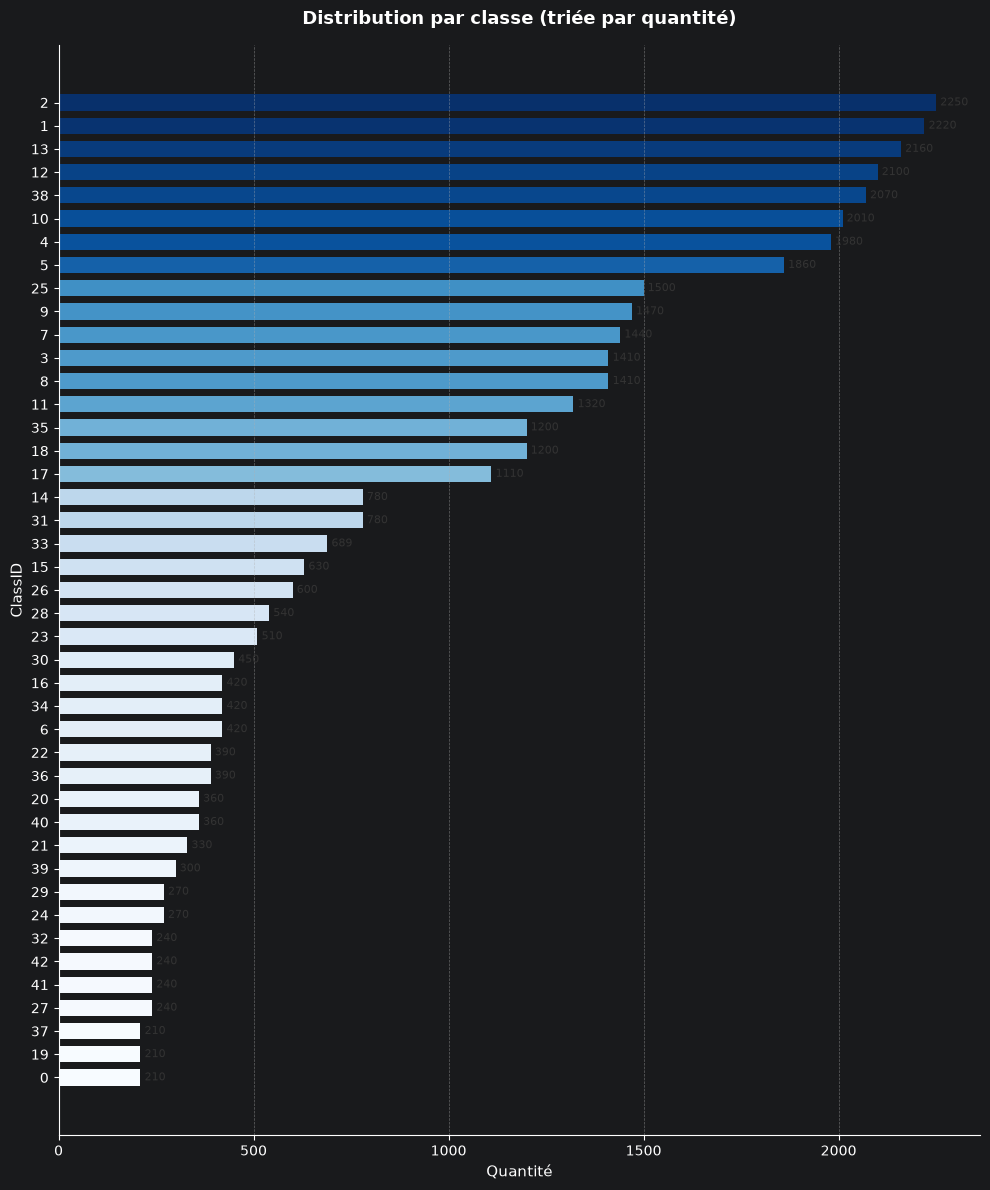

In [ ]:
biggest_class = quantity_frame[quantity_frame['Quantité'].max() == quantity_frame['Quantité']]
smallest_class = quantity_frame[quantity_frame['Quantité'].min() == quantity_frame['Quantité']]

ratio = biggest_class['Quantité'].unique()[0]/smallest_class['Quantité'].unique()[0]

print("="*50)
print("Déséquilibre des classes")
print(f"- Ratio entre la classe {biggest_class['ClassID'].unique()[0]} et la classe {smallest_class['ClassID'].unique()[0]}:  {ratio:.2f}:1")
obs.get_size_plot(quantity_frame)

# Planche d'aperçus

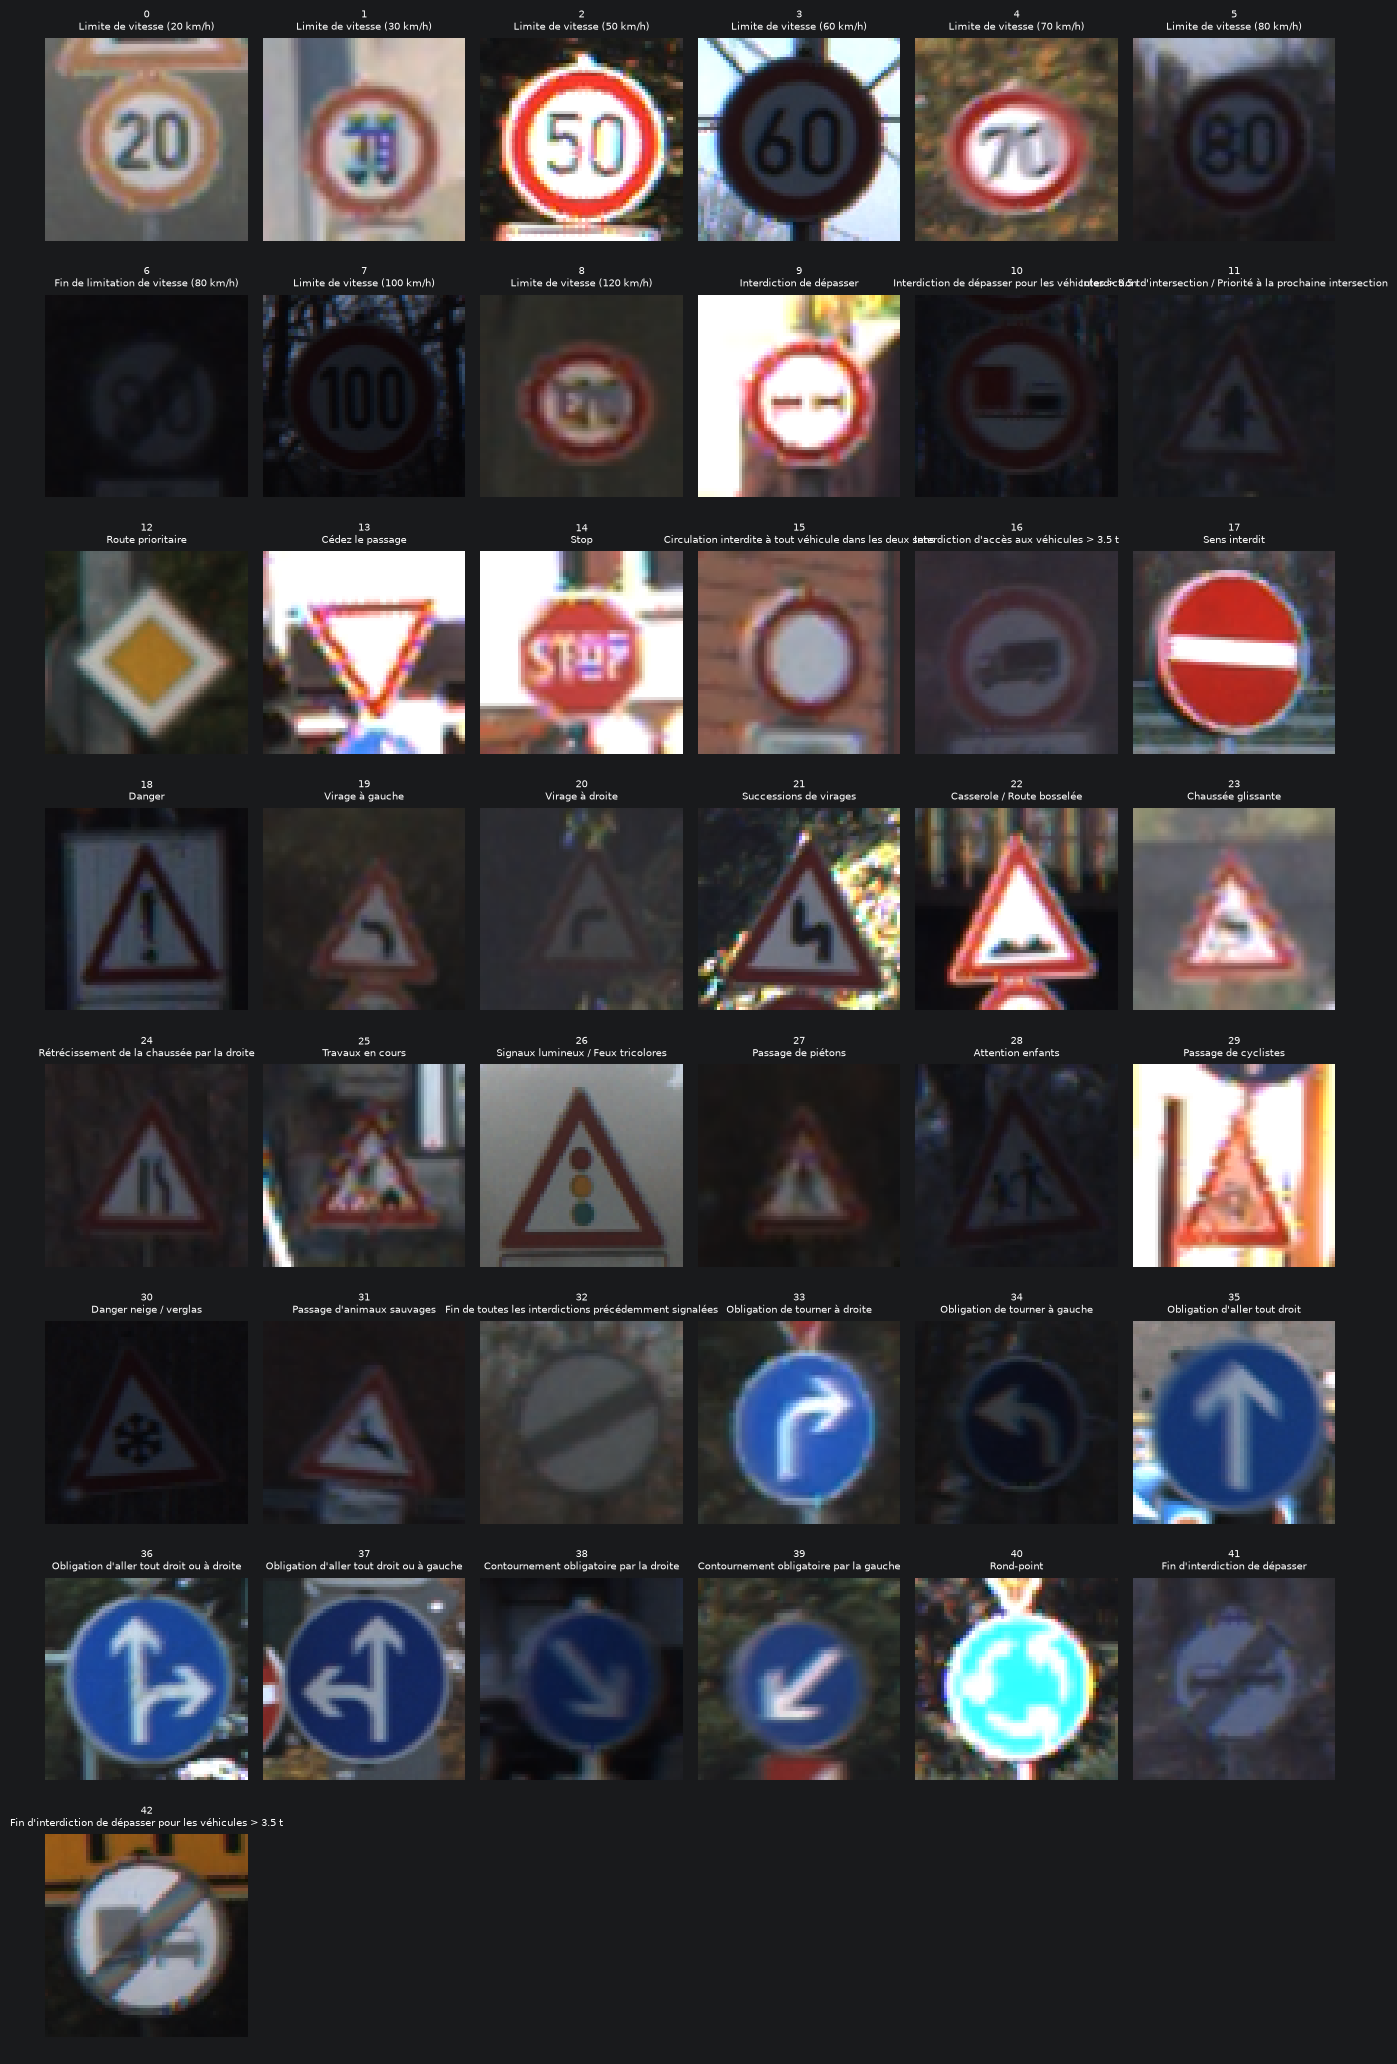

In [ ]:
# Planche d'aperçu globale
obs.create_frame(ROOT / "data/raw/gtsrb/Train", correspondance, save_path=ROOT / "reports/figures/planche_classes.png")

# Planche d'aperçus détaillées
#obs.create_every_class_frame(ROOT / "data/raw/gtsrb/Train", correspondance, save_dir=ROOT / "reports/figures/detailed_classes")

# Préparation des données
## Chemin normal

Conversion des images => redimensionnement des images => Conversion en tenseur => Sauvegarde des données

In [ ]:
from trafficsigns.config import ROOT
from trafficsigns.data.preprocessing import build_dataset, save_dataset
from pathlib import Path
from trafficsigns.config import load_config

cfg = load_config(ROOT / "configs" / "base.yaml")

raw_dir = ROOT / cfg["data"]["raw_dir"]
output_dir = ROOT / cfg["data"]["processed_dir"]
# Dataset classique
img_X, img_y, img_paths = build_dataset(raw_dir)
save_dataset(img_X, img_y, img_paths, Path.joinpath(output_dir, "train"))


## Séparation des données

20 % de validation, 80 % d'entrainement

In [ ]:
# split des valeurs

from trafficsigns.config import load_config
from trafficsigns.data.dataset import load_dataset
from trafficsigns.data.split import grouped_stratified_split, assert_no_leakage, save_split, val_fraction_per_class, extract_group_keys
from trafficsigns.config import ROOT
import numpy as np

cfg_path = Path.joinpath(ROOT, "configs", "base.yaml")
cfg = load_config(cfg_path) if cfg_path.exists() else {}
loaded_seed = cfg["seed"]
loaded_val_ratio = cfg["split"]["val_ratio"]

processed = Path.joinpath(ROOT, cfg["data"]["processed_dir"])
_, new_y, paths = load_dataset(processed, mmap=True)
new_groups = extract_group_keys(paths)

new_train_idx, new_val_idx = grouped_stratified_split(new_y, new_groups, loaded_val_ratio, loaded_seed)
assert_no_leakage(new_groups, new_train_idx, new_val_idx)
save_split(new_train_idx, new_val_idx, processed, loaded_seed, loaded_val_ratio)

print(f"train : {len(new_train_idx)} images, {len(np.unique(new_groups[new_train_idx]))} panneaux")
print(f"val   : {len(new_val_idx)} images, {len(np.unique(new_groups[new_val_idx]))} panneaux "
          f"({len(new_val_idx) / len(new_y):.1%})")
frac = val_fraction_per_class(new_y, new_val_idx)
print(f"part de validation par classe : min {frac.min():.1%}, max {frac.max():.1%}")

Le dataset GTSRB est déjà découpé en train et test. Ainsi, on ne fait que le découpage entre Train et Validation. Dans ces scripts, on s'assure qu'iil n'y a pas de fuites de données entre l'entrainement et la validation (à cause des séquences d'images).

Le dataset GTSRB est déjà découpé en train et test. Ainsi, on ne fait que le découpage entre Train et Validation. Dans ces scripts, on s'assure qu'iil n'y a pas de fuites de données entre l'entrainement et la validation (à cause des séquences d'images).

# 1. Évolution de l'architecture : Du Perceptron au CNN

Notre objectif est de classifier des panneaux de signalisation de 48x48 pixels en 43 classes (Dataset GTSRB). 
Nous avons d'abord conçu un modèle de référence (Baseline - MLP) pour valider notre pipeline de données, avant de construire un Réseau de Neurones Convolutif (CNN) capable de comprendre la géométrie des panneaux.

In [1]:
from trafficsigns.models.baseline import build_baseline_model
from trafficsigns.models.cnn import build_cnn_model

input_shape = (48, 48, 3)
num_classes = 43

## 1.1 Le Modèle de Référence (MLP)
Le modèle de base aplatit directement l'image (Flatten) en un vecteur de 6912 pixels. L'inconvénient est qu'il perd toute notion de géométrie et de contexte spatial.

In [ ]:
baseline_model = build_baseline_model(input_shape, num_classes)
baseline_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 6912)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       884,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 43)             │         5,547 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 890,411 (3.40 MB)

 Trainable params: 890,411 (3.40 MB)

 Non-trainable params: 0 (0.00 B)

## 1.2 Le Réseau de Neurones Convolutif (CNN)
Pour pallier ce problème, nous avons conçu une architecture CNN inspirée de VGG :
- **Conv2D (3x3)** : extrait les caractéristiques locales (bords, formes, chiffres).
- **MaxPooling2D (2x2)** : divise mathématiquement la taille par 2 (48->24->12->6) pour synthétiser l'information.
- **Dropout (0.5)** : désactive 50% des neurones pour forcer le modèle à généraliser et éviter l'overfitting.

In [ ]:
cnn_model = build_cnn_model(input_shape, num_classes)
cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 48, 48, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     1,179,904 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 43)             │        11,051 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,284,203 (4.90 MB)

 Trainable params: 1,284,203 (4.90 MB)

 Non-trainable params: 0 (0.00 B)

# 2. Évaluation et Courbes d'Apprentissage

Ce notebook analyse les performances finales de notre modèle CNN. Nous vérifions d'abord sa courbe de progression pendant l'entraînement, puis nous évaluons sa précision sur le jeu de test inédit à l'aide d'une matrice de confusion.

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import classification_report, confusion_matrix
import keras

from trafficsigns.config import ROOT
from trafficsigns.data.preprocessing import preprocess_single_image
from trafficsigns.utils.compute_parameters import load_mean_std

# Nouveaux chemins suite au PR de Bari
model_dir = ROOT / "models" / "test"
model_path = model_dir / "model.keras"
stats_path = model_dir / "norm_stats.npz"
test_csv = ROOT / "data" / "raw" / "gtsrb" / "Test.csv"
base_img_dir = ROOT / "data" / "raw" / "gtsrb"

## 2.1 Courbes d'Apprentissage (Loss & Accuracy)
Analyse de l'évolution de la précision et de l'erreur sur les données d'entraînement et de validation au fil des 15 époques.

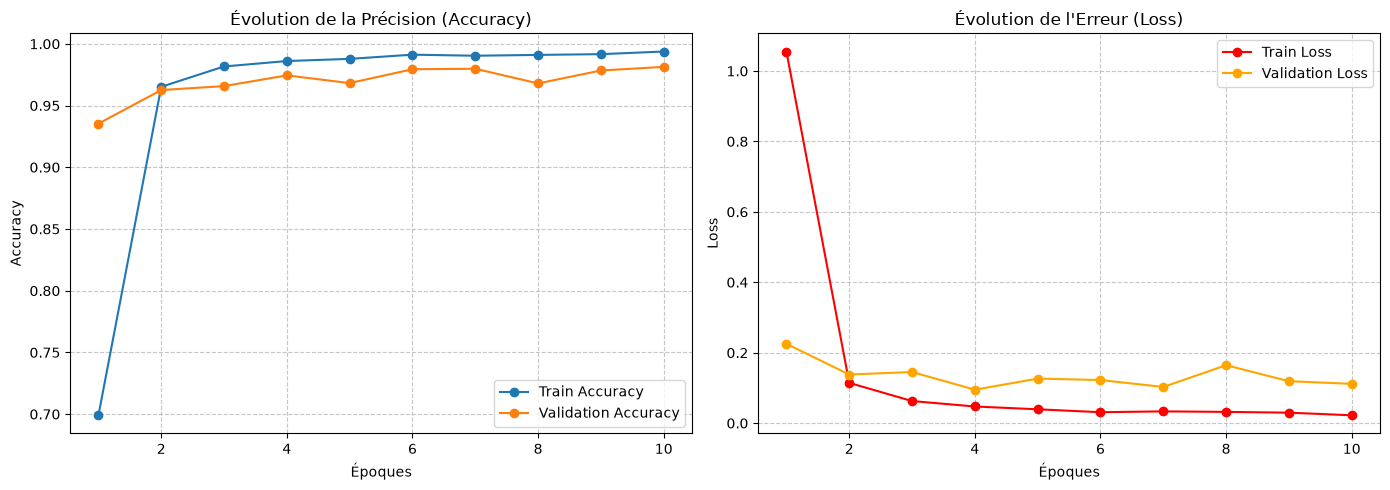

In [ ]:
history_path = model_dir / "history_epochs.csv"
df_history = pd.read_csv(history_path)

epochs = range(1, len(df_history) + 1)
train_acc = df_history['accuracy']
val_acc = df_history['val_accuracy']
train_loss = df_history['loss']
val_loss = df_history['val_loss']


plt.figure(figsize=(14, 5))

# Courbe Accuracy
plt.subplot(1, 2, 1)
plt.plot(epochs, train_acc, label='Train Accuracy', marker='o')
plt.plot(epochs, val_acc, label='Validation Accuracy', marker='o')
plt.title('Évolution de la Précision (Accuracy)')
plt.xlabel('Époques')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)

# Courbe Loss
plt.subplot(1, 2, 2)
plt.plot(epochs, train_loss, label='Train Loss', marker='o', color='red')
plt.plot(epochs, val_loss, label='Validation Loss', marker='o', color='orange')
plt.title('Évolution de l\'Erreur (Loss)')
plt.xlabel('Époques')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

## 2.2 Prédictions et Matrice de Confusion
Nous chargeons les moyennes et variances calculées spécifiquement sur le jeu d'entraînement pour normaliser le jeu de test sans créer de fuite de données (Data Leakage).

In [ ]:
model = keras.models.load_model(model_path)
df = pd.read_csv(test_csv)
mean, std = load_mean_std(stats_path)

x_test = []
y_true = df['ClassId'].values

for img_path in df['Path'].values:
    full_path = base_img_dir / img_path
    img_processed = preprocess_single_image(full_path, mean=mean, std=std)
    x_test.append(img_processed)

x_test = np.array(x_test)
y_pred_probs = model.predict(x_test)
y_pred = np.argmax(y_pred_probs, axis=1)

print(classification_report(y_true, y_pred))

395/395 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step
              precision    recall  f1-score   support

           0       1.00      0.98      0.99        60
           1       0.96      0.99      0.98       720
           2       0.95      1.00      0.97       750
           3       0.93      0.99      0.96       450
           4       0.98      0.98      0.98       660
           5       0.96      0.92      0.94       630
           6       0.99      0.89      0.94       150
           7       1.00      0.88      0.94       450
           8       0.89      0.96      0.93       450
           9       0.96      0.99      0.97       480
          10       1.00      0.98      0.99       660
          11       0.97      1.00      0.98       420
          12       0.99      0.98      0.99       690
          13       0.98      1.00      0.99       720
          14       1.00      1.00      1.00       270
          15       0.96      1.00      0.98       210
          16       1.00      0.99      

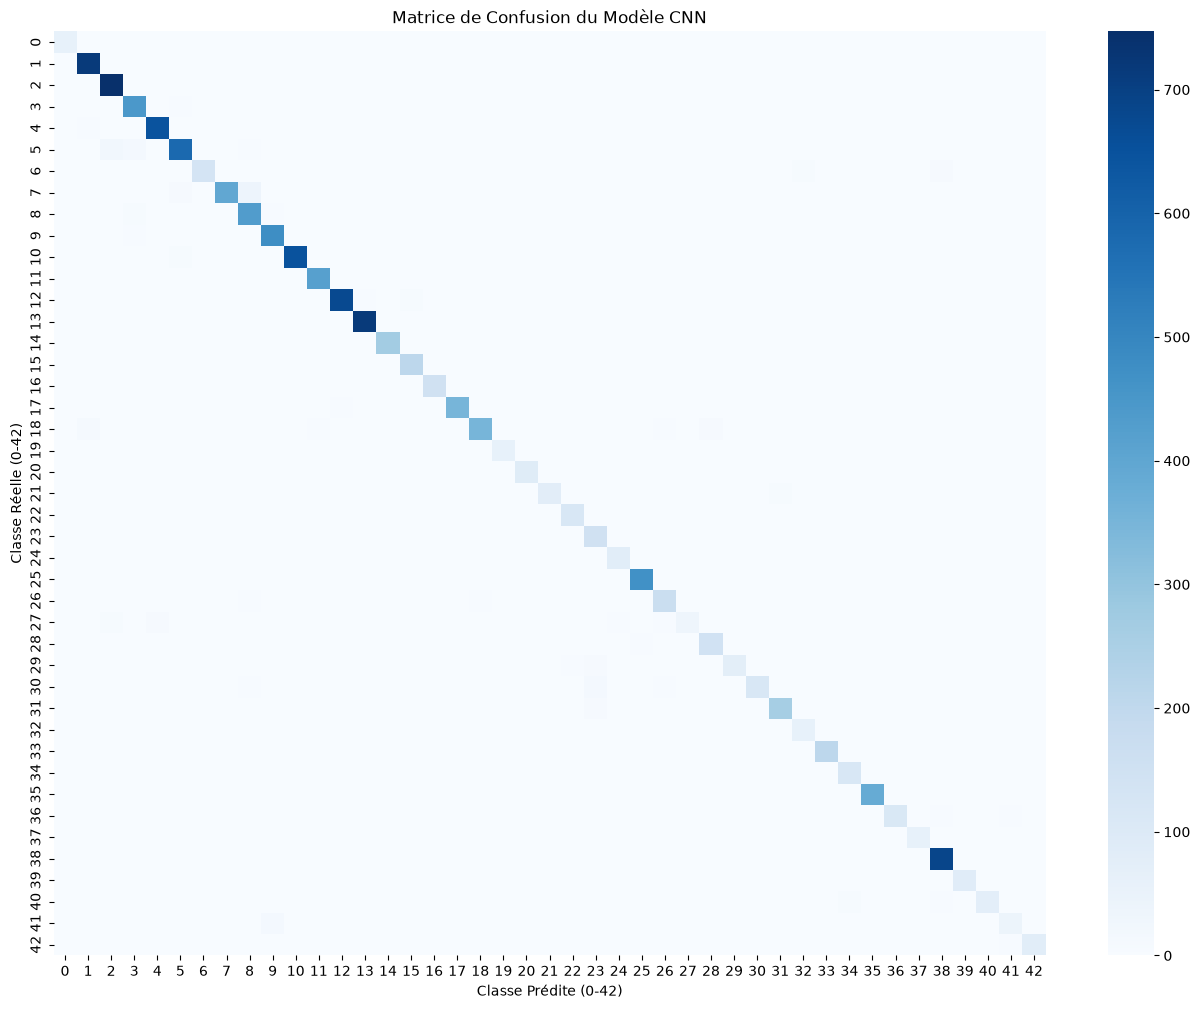

In [ ]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(16, 12))
sns.heatmap(cm, annot=False, cmap='Blues')
plt.title("Matrice de Confusion du Modèle CNN")
plt.xlabel("Classe Prédite (0-42)")
plt.ylabel("Classe Réelle (0-42)")
plt.show()

# Expériences

Différentes expériences ont été effectuées pour améliorer les performances du modèle. Les principales expériences incluent l'utilisation de différentes architectures de réseaux de neurones, l'ajout de couches de régularisation, l'ajustement des hyperparamètres et l'expérimentation avec des techniques d'augmentation de données.

## 1. Data augmentation

Le principe : équilibré les classes d'images pour éviter le sur ajustement du modèle. Pour cela, un nouveau préprocessing est nécessaire.

In [ ]:
# Nouveau préprocessing
from trafficsigns.config import ROOT, load_config
from trafficsigns.data.data_augmentation import balance_and_augment_dataset
from trafficsigns.data.preprocessing import build_dataset, save_dataset
from pathlib import Path

cfg = load_config(Path(ROOT) / "configs" / "exp_configs" / "db_aug.yaml")

# Creation par data augmentation
# 1. Chargement/Build brut
X, y, paths = build_dataset(raw_dir)
print(f"Dataset brut : {X.shape[0]} images au total.")

# 2. Augmentation & Rééquilibrage (ex: 2000 images par classe = 86 000 images)
X_aug, y_aug, paths_aug = balance_and_augment_dataset(X, y, paths, target_per_class=2000)

# 3. Sauvegarde dans le dossier processed/train sous forme .npy
save_dataset(X_aug, y_aug, paths_aug, Path.joinpath(output_dir, "train_augmented"))
print(f"Dataset augmenté sauvegardé sous '{output_dir}'.")
print(f"x_augmented shape: {X_aug.shape}")
print(f"y_augmented shape: {y_aug.shape}")

In [ ]:
# split des valeurs

from trafficsigns.config import load_config
from trafficsigns.data.dataset import load_dataset
from trafficsigns.data.split import grouped_stratified_split, assert_no_leakage, save_split, val_fraction_per_class, extract_group_keys
from trafficsigns.config import ROOT
import numpy as np

cfg_path = Path.joinpath(ROOT, "configs", "exp_configs", "db_aug.yaml")
cfg = load_config(cfg_path) if cfg_path.exists() else {}
loaded_seed = cfg["seed"]
loaded_val_ratio = cfg["split"]["val_ratio"]

processed = Path.joinpath(ROOT, cfg["data"]["processed_dir"])
_, new_y, paths = load_dataset(processed, mmap=True)
new_groups = extract_group_keys(paths)

new_train_idx, new_val_idx = grouped_stratified_split(new_y, new_groups, loaded_val_ratio, loaded_seed)
assert_no_leakage(new_groups, new_train_idx, new_val_idx)
save_split(new_train_idx, new_val_idx, processed, loaded_seed, loaded_val_ratio)

print(f"train : {len(new_train_idx)} images, {len(np.unique(new_groups[new_train_idx]))} panneaux")
print(f"val   : {len(new_val_idx)} images, {len(np.unique(new_groups[new_val_idx]))} panneaux "
          f"({len(new_val_idx) / len(new_y):.1%})")
frac = val_fraction_per_class(new_y, new_val_idx)
print(f"part de validation par classe : min {frac.min():.1%}, max {frac.max():.1%}")

In [ ]:
# Création du modèle selon la configuration du fichier
from trafficsigns.config import ROOT, load_config
from trafficsigns.training.train import train_model

cfg_path = Path.joinpath(ROOT, "configs"/"exp_configs"/"db_aug.yaml")
cfg = load_config(cfg_path) if cfg_path.exists() else {}

# Extraire les sous-sections du YAML avec valeurs de secours (fallbacks)
data_cfg = cfg.get("data", {})
model_cfg = cfg.get("model", {})

train_model(
    model_to_train=model_cfg.get("type", "baseline"),
    data_dir=Path.joinpath(ROOT, data_cfg.get("processed_dir", "data/processed/train")),
    model_save_path=Path.joinpath(ROOT, model_cfg.get("dir", "models/new_model")),
    epochs=data_cfg.get("epochs", 15),
    batch_size=data_cfg.get("batch_size", 32)
)

## 2. Changement de taille de batch

On décide de changer la taille de batch pour voir si cela améliore les performances du modèle. On passe de 32 à 8 images. 

In [ ]:
# Création du modèle selon la configuration du fichier
from trafficsigns.config import ROOT, load_config
from trafficsigns.training.train import train_model

cfg_path = Path.joinpath(ROOT, "configs"/"exp_configs"/"cfg_batch.yaml")
cfg = load_config(cfg_path) if cfg_path.exists() else {}

# Extraire les sous-sections du YAML avec valeurs de secours (fallbacks)
data_cfg = cfg.get("data", {})
model_cfg = cfg.get("model", {})

train_model(
    model_to_train=model_cfg.get("type", "baseline"),
    data_dir=Path.joinpath(ROOT, data_cfg.get("processed_dir", "data/processed/train")),
    model_save_path=Path.joinpath(ROOT, model_cfg.get("dir", "models/new_model")),
    epochs=data_cfg.get("epochs", 15),
    batch_size=data_cfg.get("batch_size", 32)
)

## 3. Changement de modèle

On change les paramètres du CNN : 


In [ ]:
# Création du modèle selon la configuration du fichier
from trafficsigns.config import ROOT, load_config
from trafficsigns.training.train import train_model

cfg_path = Path.joinpath(ROOT, "configs"/"exp_configs"/"base_cnn.yaml")
cfg = load_config(cfg_path) if cfg_path.exists() else {}

# Extraire les sous-sections du YAML avec valeurs de secours (fallbacks)
data_cfg = cfg.get("data", {})
model_cfg = cfg.get("model", {})

print(data_cfg.get("processed_dir", "data/processed/train"))
train_model(
    model_to_train=model_cfg.get("type", "baseline"),
    data_dir=Path.joinpath(ROOT, data_cfg.get("processed_dir", "data/processed/train")),
    model_save_path=Path.joinpath(ROOT, model_cfg.get("dir", "models/new_model")),
    epochs=data_cfg.get("epochs", 15),
    batch_size=data_cfg.get("batch_size", 32)
)

# 3. Extension : Détection de panneaux dans une scène (avec YOLO)

Jusqu'à présent, notre CNN (Classification) travaillait sur des images parfaitement recadrées. Dans la réalité d'un véhicule autonome, la caméra filme une scène complète. Il nous faut donc un modèle capable de **trouver** le panneau avant de le **lire**.

C'est le rôle de **YOLO (You Only Look Once)**, un modèle de détection d'objets extrêmement rapide.

### Le Pipeline de traitement :
1. **Détection (YOLO)** : Analyse l'image complète et trace une boîte (Bounding Box) autour des objets ressemblant à des panneaux.
2. **Extraction & Prétraitement** : Découpage de la boîte et application de la même normalisation que lors de notre entraînement (48x48 pixels).
3. **Classification (Notre CNN)** : Le CNN prend le relais sur l'image découpée et prédit la classe exacte du panneau.

In [ ]:
import cv2
import numpy as np
import keras
import matplotlib.pyplot as plt
from ultralytics import YOLO

from trafficsigns.config import ROOT
from trafficsigns.data.preprocessing import resize_img, normalize
from trafficsigns.utils.compute_parameters import load_mean_std

## 3.1 Chargement des modèles et de la scène
Nous utilisons ici un modèle YOLO standard (`yolov8n.pt`). Comme le précise le sujet, ce modèle généraliste n'est pas un expert en panneaux routiers (il connaît surtout le panneau STOP). Il servira donc de "localisateur" général, et notre CNN fera le travail d'expert.

In [ ]:
scene_image_path = ROOT / "data" / "raw" / "test_scene.jpg"
cnn_model_path = ROOT / "models" / "test" / "model.keras"
stats_path = ROOT / "models" / "test" / "norm_stats.npz"

print("Chargement de YOLO...")
yolo_detector = YOLO("yolov8n.pt") 

print("Chargement de notre CNN...")
cnn_classifier = keras.models.load_model(cnn_model_path)
mean, std = load_mean_std(stats_path)

Chargement de YOLO...
Chargement de notre CNN...


## 3.2 Inférence : Le test en conditions réelles
Nous allons passer notre image de test dans la chaîne de traitement complète. Observez comment la Bounding Box est découpée mathématiquement via NumPy avant d'être envoyée au CNN.

YOLO a trouvé 3 objets potentiels.


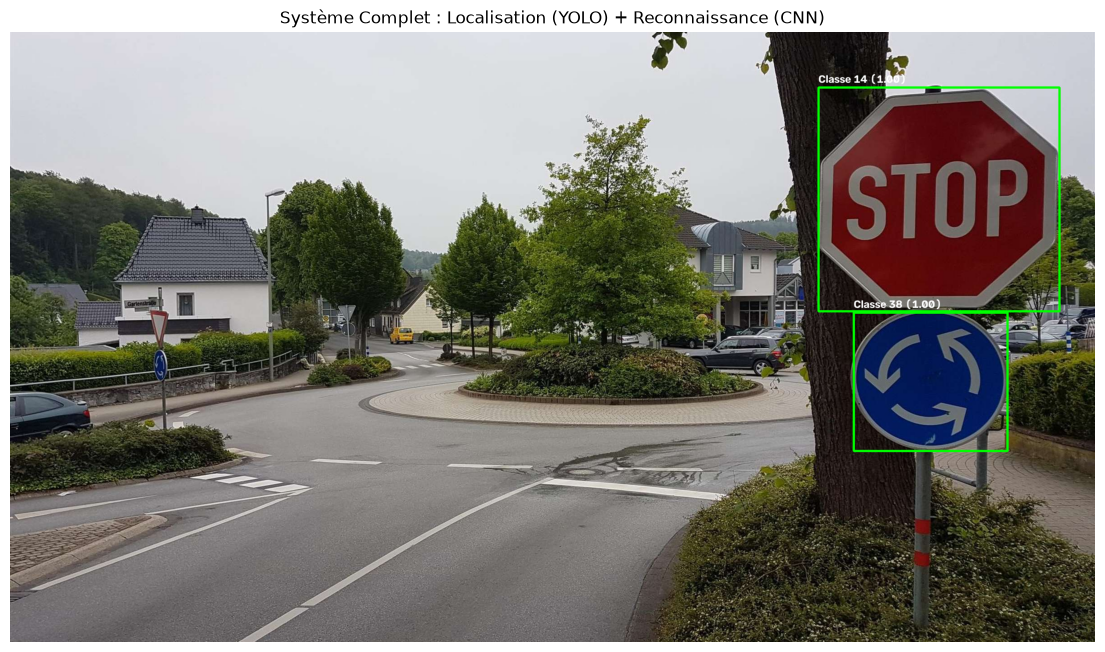

In [ ]:
img_bgr = cv2.imread(str(scene_image_path))
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
img_result = img_rgb.copy()

results = yolo_detector(img_rgb, verbose=False)
boxes = results[0].boxes
print(f"YOLO a trouvé {len(boxes)} objets potentiels.")

for box in boxes:
    x1, y1, x2, y2 = map(int, box.xyxy[0])
    conf = float(box.conf[0])
    
    if conf < 0.5:
        continue

    cropped_sign = img_rgb[y1:y2, x1:x2]
    if cropped_sign.size == 0:
        continue

    processed_sign = resize_img(cropped_sign, (48, 48))
    processed_sign = normalize(processed_sign, mean=mean, std=std)
    input_tensor = np.expand_dims(processed_sign, axis=0)

    predictions = cnn_classifier.predict(input_tensor, verbose=0)
    predicted_class = np.argmax(predictions[0])
    cnn_confidence = np.max(predictions[0])

    cv2.rectangle(img_result, (x1, y1), (x2, y2), (0, 255, 0), 3)
    label = f"Classe {predicted_class} ({cnn_confidence:.2f})"
    cv2.putText(img_result, label, (x1, max(20, y1 - 10)), 
                cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 255, 255), 2)

plt.figure(figsize=(14, 10))
plt.imshow(img_result)
plt.axis('off')
plt.title("Système Complet : Localisation (YOLO) + Reconnaissance (CNN)")
plt.show()

## 3.3 Analyse des résultats
Comme attendu, la communication entre les deux modèles est un succès :
- **Localisation réussie :** YOLO a trouvé la position exacte des deux panneaux dans l'espace.
- **Classification experte :** YOLO (qui ne connaît pas les ronds-points) a cru voir deux panneaux STOP. Notre CNN a corrigé le tir en identifiant le vrai panneau STOP comme **Classe 14 (100% de confiance)** et le panneau de contournement comme **Classe 38 (panneau d'obligation bleu, 100% de confiance)**. 

*Conclusion : Pour passer à l'étape industrielle, il nous suffirait désormais de fine-tuner YOLO (Transfer Learning) sur un dataset spécialisé dans la détection globale de panneaux (pour qu'il ne rate aucun panneau en bord de route), notre CNN se chargeant du reste de l'analyse métier.*